# CA-DMAR-R benchmark: exploratory data analysis

Compares three algorithms — **Greedy**, **DMAR** (baseline, `dmar`) and **CA-DMAR-R** (`ca_dmar_r`, capacity-aware) — on grids of side 10, 20 and 30, at α ∈ {0.25, 0.5, 0.75}.

**How to run:** put this notebook in (or above) the folder holding the nine `benchmark-<S>x<S>-alpha-<A>.csv` files and run all cells. Set `DATA_DIR` in the first code cell if they live elsewhere.

**Contents**
1. Load and integrity checks
2. Experimental design and what the columns do (and don't) tell us
3. Headline comparison (completion, unresolved tasks, rounds)
4. Time to completion
5. Effect of grid size, task density and sensing radius
6. Paired comparison CA-DMAR-R vs DMAR on identical scenarios
7. Where the movement goes
8. Sensitivity to α
9. Failure structure: which instances never finish
10. Rejected assignments
11. Clustering behaviour
12. Map coverage
13. Correlations
14. Findings, caveats and suggested next experiments

In [1]:
import re, glob, os, warnings
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")

DATA_DIR = "."   # searched recursively for benchmark-<S>x<S>-alpha-<A>.csv

# ---- visual style: one colour per algorithm, fixed everywhere (validated palette) ----
SURFACE, INK, INK2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
COL  = {"greedy": "#2a78d6", "dmar": "#eb6834", "ca_dmar_r": "#1baf7a"}
LBL  = {"greedy": "Greedy", "dmar": "DMAR (baseline)", "ca_dmar_r": "CA-DMAR-R"}
MRK  = {"greedy": "s", "dmar": "o", "ca_dmar_r": "^"}
ALGS = ["greedy", "dmar", "ca_dmar_r"]
SEQ  = LinearSegmentedColormap.from_list("seq", ["#e7f0fc", "#6da7ec", "#2a78d6", "#0d366b"])
DIV  = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#eb6834"])
mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.titlecolor": INK, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False, "font.size": 10, "figure.dpi": 110, "lines.linewidth": 2,
})
pd.set_option("display.width", 200, "display.max_columns", 60, "display.float_format", "{:,.3f}".format)

rng = np.random.default_rng(0)
def boot(x, n=4000):
    # mean and 95% CI, resampling per-instance values (the independent unit)
    x = np.asarray(x, float); x = x[~np.isnan(x)]
    m = x[rng.integers(0, len(x), (n, len(x)))].mean(1)
    return x.mean(), *np.percentile(m, [2.5, 97.5])

# ---- load ----
pat = re.compile(r"benchmark-(\d+)x(\d+)-alpha-([0-9.]+)\.csv$")
files = sorted(f for f in glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True) if pat.search(f))
assert files, "no benchmark CSVs found under DATA_DIR"
frames = []
for f in files:
    m = pat.search(f); df = pd.read_csv(f); df["file"] = os.path.basename(f)
    assert (df.side == int(m[1])).all() and np.allclose(df.alpha, float(m[3])), f"file name disagrees with contents: {f}"
    frames.append(df)
d = pd.concat(frames, ignore_index=True)
K = ["side", "instance", "run", "sensing_radius", "task_agent_ratio"]   # one simulated scenario

MAX_ROUNDS = int(d.rounds.max())
d["tpa"] = d.task_count / d.agent_count
d["ok"] = d.unresolved_tasks.eq(0)
d["inst"] = d.side.astype(str) + "|" + d.instance.astype(str) + "|" + d.task_agent_ratio.astype(str)
d["rel_radius"] = d.sensing_radius / d.side
d["coverage"] = d.observed_traversable_cells / d.total_traversable_cells
d["explore_share"] = d.exploration_movement / d.movement_cost
d["excl_share"] = d.exhausted_cluster_memberships / d.cluster_memberships.replace(0, np.nan)

print(f"{len(files)} files, {len(d):,} rows, {d.shape[1]} columns; round cap = {MAX_ROUNDS}")
display(d.groupby(["side", "alpha", "algorithm"]).size().unstack().rename_axis(None, axis=1))

9 files, 9,720 rows, 48 columns; round cap = 5000


ca_dmar_r  dmar  greedy
side alpha                         
10   0.250        360   360     360
     0.500        360   360     360
     0.750        360   360     360
20   0.250        360   360     360
     0.500        360   360     360
     0.750        360   360     360
30   0.250        360   360     360
     0.500        360   360     360
     0.750        360   360     360

## 1. Integrity checks

Every check below should print `True`. They also establish facts the later analysis relies on (for example that greedy and DMAR do not depend on α).

In [2]:
nonca = d[d.algorithm != "ca_dmar_r"]
checks = {
 "no missing values":                                      d.isna().sum().sum() == 0,
 "one row per (algorithm, alpha, scenario)":               not d.duplicated(["algorithm", "alpha"] + K).any(),
 "completed + unresolved = task_count":                    (d.completed_tasks + d.unresolved_tasks == d.task_count).all(),
 "completed + remaining capacity = initial capacity":      (d.completed_tasks + d.remaining_capacity == d.initial_capacity).all(),
 "initial capacity = task_count (ZERO slack)":             (d.initial_capacity == d.task_count).all(),
 "task_serving + exploration = movement_cost":             (d.task_serving_movement + d.exploration_movement == d.movement_cost).all(),
 "eligible + exhausted = movement_cost":                   (d.eligible_movement + d.exhausted_movement == d.movement_cost).all(),
 "greedy/DMAR results identical across alpha files":       (nonca.groupby(["algorithm"] + K)[["movement_cost", "rounds", "unresolved_tasks"]].nunique().max() == 1).all(),
 "every failed run ran to the round cap":                  (d[~d.ok].rounds == MAX_ROUNDS).all(),
 "capacity violations are all zero":                       (d.capacity_violations.eq(0) & d.execution_capacity_violations.eq(0)).all(),
}
display(pd.Series(checks, name="passes").to_frame())
print("Runs that finished on exactly the final round (counted as completed):", int((d.ok & (d.rounds == MAX_ROUNDS)).sum()))

,passes
no missing values,True
"one row per (algorithm, alpha, scenario)",True
completed + unresolved = task_count,True
completed + remaining capacity = initial capacity,True
initial capacity = task_count (ZERO slack),True
task_serving + exploration = movement_cost,True
eligible + exhausted = movement_cost,True
greedy/DMAR results identical across alpha files,True
every failed run ran to the round cap,True
capacity violations are all zero,True


Runs that finished on exactly the final round (counted as completed): 3


## 2. Experimental design and column caveats

Each scenario is a map/agent/task layout (`side`, `instance`, task:agent ratio) simulated with a given sensing radius and random `run` seed. The **independent unit is the instance** (side × instance × ratio = 45 layouts); the 8 radii × 3 runs inside an instance reuse the same map, so rows within an instance are *not* independent. All confidence intervals below therefore resample the 45 instances, not the 1,080 rows.

Because greedy and DMAR do not depend on α, their rows are duplicated across the three α files. They are kept once per scenario where it matters; instance-level averages are unaffected by the duplication.

In [3]:
design = d.groupby("side").agg(agents=("agent_count", "first"), instances=("inst", "nunique"),
                               radii=("sensing_radius", "nunique"), runs=("run", "nunique"))
display(design)
display(d.groupby(["task_agent_ratio"]).agg(tasks_per_agent=("tpa", "first")).sort_values("tasks_per_agent"))

# columns that carry no information in this data set
const = [c for c in d.columns if d[c].nunique() == 1]
print("Constant columns (no information):", const)

# counters that contradict each other
print("\nrows with exhausted_cluster_memberships > 0          :", f"{(d.exhausted_cluster_memberships > 0).mean():.1%}")
print("rows with exhausted_clustered_rounds   > 0          :", f"{(d.exhausted_clustered_rounds > 0).mean():.1%}")
print("rows with exhausted_agent_rounds       > 0          :", f"{(d.exhausted_agent_rounds > 0).mean():.1%}")
print("rows with exhausted_movement           > 0          :", f"{(d.exhausted_movement > 0).mean():.1%}")
print("rows with exhausted_exploration flag set            :", f"{d.exhausted_exploration.mean():.1%}")

,agents,instances,radii,runs
side,,,,
10,10,15,8,3
20,20,15,8,3
30,30,15,8,3


,tasks_per_agent
task_agent_ratio,
2:1,0.500
1:1,1.000
1:2,2.000


Constant columns (no information): ['capacity_violations', 'execution_capacity_violations', 'simulated_capacity_rejections', 'exhausted_movement', 'exhausted_clustered_movement', 'exhausted_unclustered_movement', 'exhausted_exploration', 'soac_mode', 'assignment_mode', 'exhausted_clustered_rounds']

rows with exhausted_cluster_memberships > 0          : 99.0%
rows with exhausted_clustered_rounds   > 0          : 0.0%
rows with exhausted_agent_rounds       > 0          : 100.0%
rows with exhausted_movement           > 0          : 0.0%
rows with exhausted_exploration flag set            : 100.0%


**Read these caveats before interpreting anything:**

* **Zero capacity slack.** Total capacity equals the task count in every run, so `unresolved_tasks` always equals unused capacity. One task left unserved is simultaneously one unit of capacity wasted.
* **Right-censoring.** Every unfinished run stops at the 5,000-round cap, so its `rounds` and `movement_cost` are lower bounds. Cost and rounds are only comparable on scenarios where both algorithms finished (section 6), otherwise the analysis would favour whoever fails early.
* **Exhausted-agent counters are internally inconsistent.** Exhausted agents are counted as cluster members, yet `exhausted_clustered_rounds` and `exhausted_movement` are 0 in every row, even though the `exhausted_exploration` flag is 1 everywhere. Either exhausted agents never move or those counters are not being incremented. This should be checked in the simulator; the analysis below does not rely on them.
* `soac_mode`, `assignment_mode` and `exhausted_exploration` are constant, so there is no ablation information in this data.

## 3. Headline comparison

Instance-level means with 95% bootstrap CIs over the 45 instances. CA-DMAR-R is pooled over the three α values (section 8 shows α matters little).

metric,Completion rate,"Rounds (mean, capped at 5000)",Unresolved tasks (mean)
algorithm,,,
Greedy,0.583,"2,863.980",1.132
DMAR (baseline),0.600,"2,819.588",1.010
CA-DMAR-R,0.806,"2,004.742",0.371


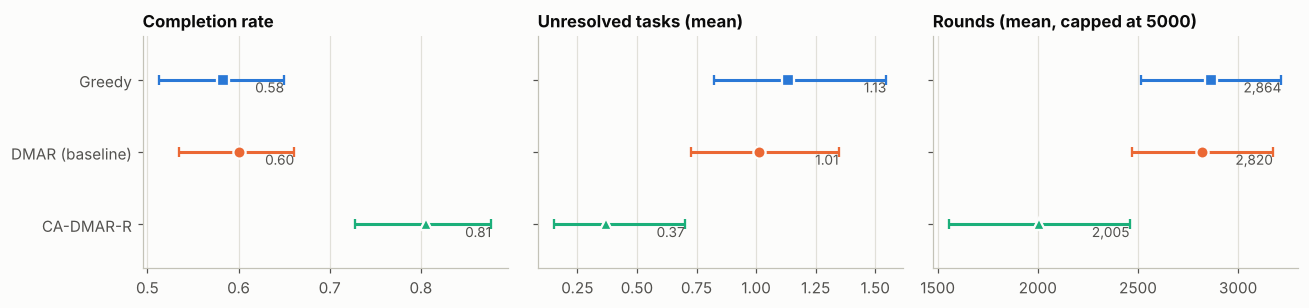

CA-DMAR-R minus DMAR completion rate (per instance): mean +0.206, 95% CI [+0.162, +0.253]


In [4]:
def inst_level(col):
    return d.groupby(["algorithm", "inst"])[col].mean().unstack(0)   # 45 rows x algorithms

rows = []
for col, name in [("ok", "Completion rate"), ("unresolved_tasks", "Unresolved tasks (mean)"), ("rounds", "Rounds (mean, capped at 5000)")]:
    t = inst_level(col)
    for a in ALGS:
        m, lo, hi = boot(t[a]); rows.append((name, LBL[a], m, lo, hi))
H = pd.DataFrame(rows, columns=["metric", "algorithm", "mean", "lo", "hi"])
display(H.pivot(index="algorithm", columns="metric", values="mean").loc[[LBL[a] for a in ALGS]])

fig, axs = plt.subplots(1, 3, figsize=(12, 2.9))
for ax, (name, g) in zip(axs, H.groupby("metric", sort=False)):
    for i, a in enumerate(ALGS):
        r = g[g.algorithm == LBL[a]].iloc[0]
        ax.errorbar(r["mean"], i, xerr=[[r["mean"] - r.lo], [r.hi - r["mean"]]], fmt=MRK[a], color=COL[a], ms=8, capsize=3, mec=SURFACE, mew=1.5)
        ax.text(r.hi, i + 0.22, f"{r['mean']:.2f}" if r["mean"] < 100 else f"{r['mean']:,.0f}", ha="right", va="bottom", fontsize=9, color=INK2)
    ax.set_yticks(range(3)); ax.set_yticklabels([LBL[a] for a in ALGS] if ax is axs[0] else [""] * 3)
    ax.set_ylim(2.6, -0.6); ax.set_title(name); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

# Paired difference of completion rate, per instance
t = inst_level("ok"); diff = (t.ca_dmar_r - t.dmar).values
bm = diff[rng.integers(0, len(diff), (4000, len(diff)))].mean(1)
print(f"CA-DMAR-R minus DMAR completion rate (per instance): mean {diff.mean():+.3f}, 95% CI [{np.percentile(bm, 2.5):+.3f}, {np.percentile(bm, 97.5):+.3f}]")

## 4. Time to completion

Fraction of runs completed by round *t*. Because every unfinished run is censored at the same cap, this is exactly the Kaplan–Meier complement, and the plateau height is the share of runs that never finish.

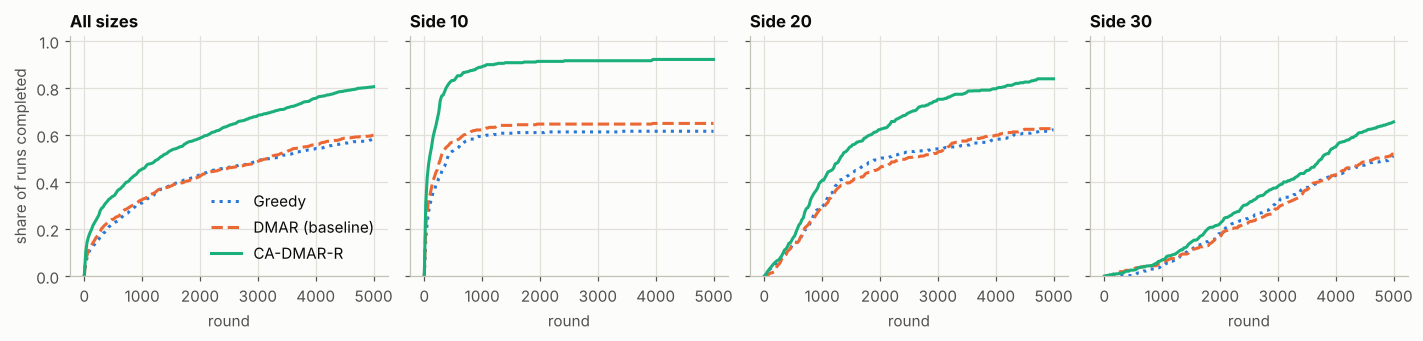

Median rounds among runs that finished (selection-biased: only finishers):


algorithm,Greedy,DMAR (baseline),CA-DMAR-R
side,,,
10,100.000,74.000,64.000
20,"1,056.000","1,103.000","1,052.000"
30,"2,587.500","2,796.000","2,620.000"


In [5]:
grid = np.arange(0, MAX_ROUNDS + 1, 25)
fig, axs = plt.subplots(1, 4, figsize=(13, 3.2), sharey=True)
for ax, (title, sub) in zip(axs, [("All sizes", d)] + [(f"Side {s}", d[d.side == s]) for s in sorted(d.side.unique())]):
    for a in ALGS:
        r = sub[(sub.algorithm == a) & sub.ok].rounds.values; n = (sub.algorithm == a).sum()
        y = np.searchsorted(np.sort(r), grid, side="right") / n
        ax.plot(grid, y, color=COL[a], label=LBL[a], ls={"greedy": ":", "dmar": "--", "ca_dmar_r": "-"}[a])
    ax.set_title(title); ax.set_xlabel("round"); ax.set_ylim(0, 1.02)
axs[0].set_ylabel("share of runs completed"); axs[0].legend(loc="lower right")
plt.tight_layout(); plt.show()

med = d[d.ok].groupby(["side", "algorithm"]).rounds.median().unstack()[ALGS].rename(columns=LBL)
print("Median rounds among runs that finished (selection-biased: only finishers):"); display(med)

## 5. Grid size, task density and sensing radius

Failure rate (1 − completion) by factor, instance-level means with 95% CIs. Sensing radius is confounded with grid size: a radius of 8 sees most of a 10×10 map but a small part of a 30×30 one, so the last panel also shows a side × radius heatmap.

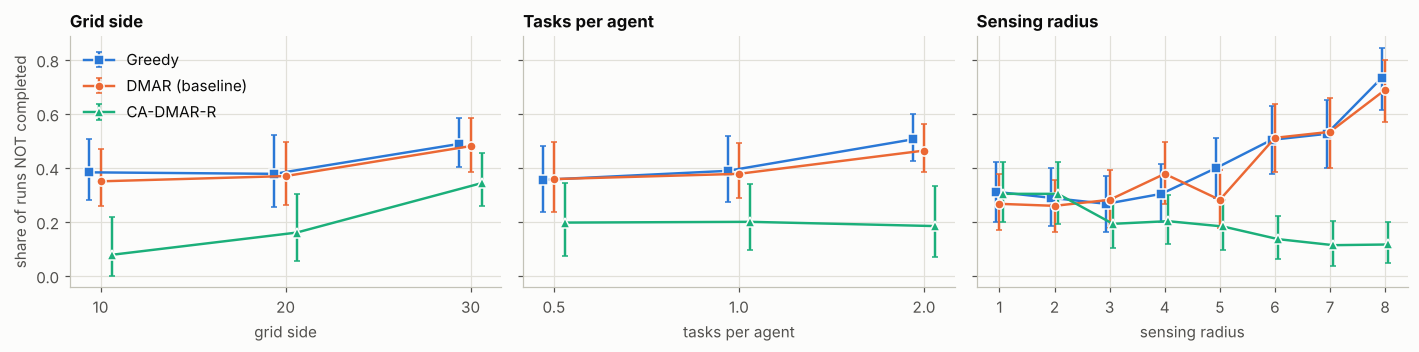

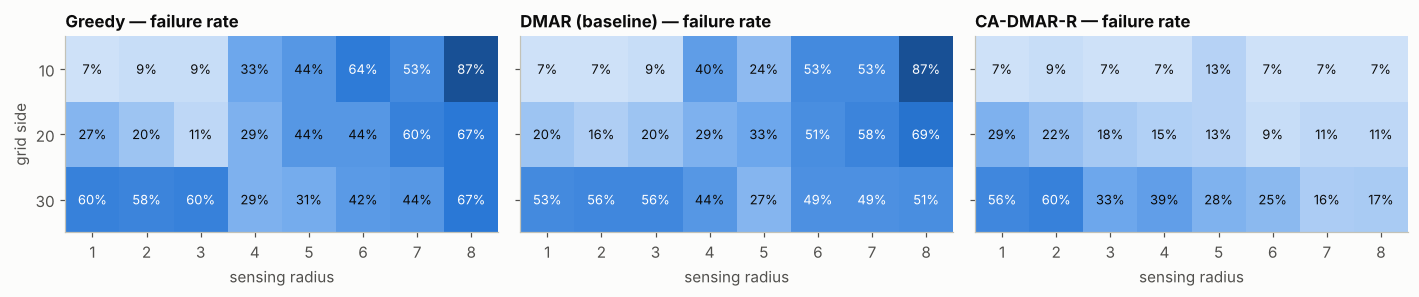

In [6]:
d["fail"] = (~d.ok).astype(float)
fig, axs = plt.subplots(1, 3, figsize=(13, 3.3), sharey=True)
for ax, (col, title) in zip(axs, [("side", "Grid side"), ("tpa", "Tasks per agent"), ("sensing_radius", "Sensing radius")]):
    lv = sorted(d[col].unique())
    for a in ALGS:
        pts = []
        for v in lv:
            s = d[(d.algorithm == a) & (d[col] == v)].groupby("inst").fail.mean()
            pts.append(boot(s))
        pts = np.array(pts)
        x = np.arange(len(lv)) + {"greedy": -0.06, "dmar": 0, "ca_dmar_r": 0.06}[a]
        ax.errorbar(x, pts[:, 0], yerr=[pts[:, 0] - pts[:, 1], pts[:, 2] - pts[:, 0]], color=COL[a], marker=MRK[a], ms=6,
                    capsize=2, label=LBL[a], lw=1.6, mec=SURFACE, mew=1)
    ax.set_xticks(range(len(lv))); ax.set_xticklabels(lv); ax.set_title(title); ax.set_xlabel(title.lower())
axs[0].set_ylabel("share of runs NOT completed"); axs[0].legend(); plt.tight_layout(); plt.show()

fig, axs = plt.subplots(1, 3, figsize=(13, 2.8), sharey=True)
for ax, a in zip(axs, ALGS):
    M = d[d.algorithm == a].groupby(["side", "sensing_radius"]).fail.mean().unstack()
    im = ax.imshow(M.values, cmap=SEQ, vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(M.shape[1])); ax.set_xticklabels(M.columns); ax.set_yticks(range(M.shape[0])); ax.set_yticklabels(M.index)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, f"{M.values[i, j]:.0%}", ha="center", va="center", fontsize=8.5, color="white" if M.values[i, j] > 0.45 else INK)
    ax.set_title(f"{LBL[a]} — failure rate"); ax.set_xlabel("sensing radius"); ax.grid(False)
axs[0].set_ylabel("grid side"); plt.tight_layout(); plt.show()

## 6. Paired comparison: CA-DMAR-R vs DMAR on identical scenarios

Every CA-DMAR-R run (per α) is matched to the DMAR run on the same map, agents, radius and seed. Scenarios fall into four outcomes. Cost and rounds are then compared **only where both finished**, as geometric-mean ratios (ratio < 1 means CA-DMAR-R is cheaper), with CIs from resampling instances.

outcome,both complete,only CA-DMAR-R,only DMAR,neither
side,,,,
10,63.9%,28.3%,1.1%,6.7%
20,57.3%,26.7%,5.7%,10.3%
30,39.2%,26.5%,12.8%,21.6%
all,53.5%,27.2%,6.5%,12.8%


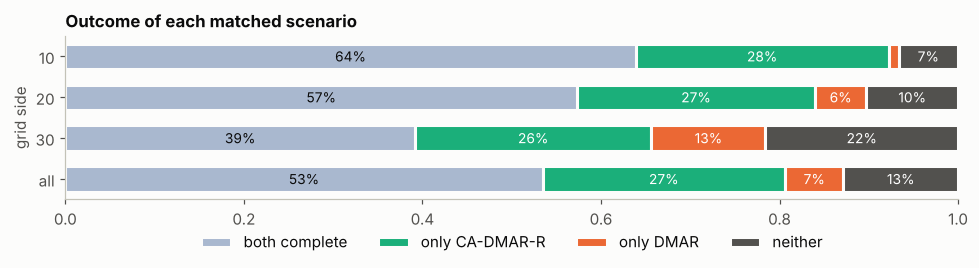

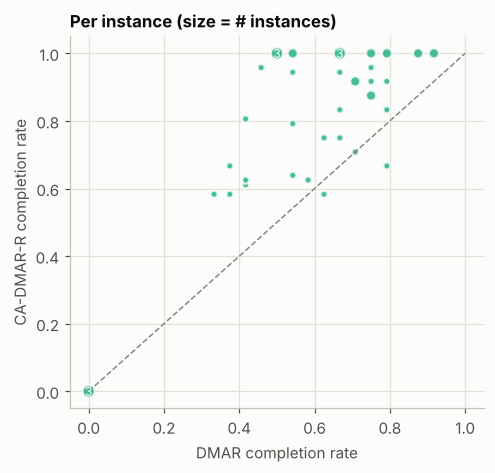

instances: CA better 39, tie 4, DMAR better 2
Wilcoxon signed-rank on per-instance completion difference: p = 5.9e-08


In [7]:
cols = ["ok", "rounds", "movement_cost", "task_serving_movement", "unresolved_tasks"]
B = d[d.algorithm == "dmar"].drop_duplicates(K)[K + cols]
CA = d[d.algorithm == "ca_dmar_r"][K + ["alpha", "inst"] + cols]
P = CA.merge(B, on=K, suffixes=("", "_b"))
P["outcome"] = np.select([P.ok & P.ok_b, P.ok & ~P.ok_b, ~P.ok & P.ok_b],
                         ["both complete", "only CA-DMAR-R", "only DMAR"], "neither")
ORDER = ["both complete", "only CA-DMAR-R", "only DMAR", "neither"]
OC = {"both complete": "#a9b8cf", "only CA-DMAR-R": "#1baf7a", "only DMAR": "#eb6834", "neither": "#52514e"}
tab = pd.crosstab(P.side, P.outcome, normalize="index")[ORDER]
tab.loc["all"] = P.outcome.value_counts(normalize=True)[ORDER]
display(tab.style.format("{:.1%}"))

fig, ax = plt.subplots(figsize=(9, 2.6)); left = np.zeros(len(tab))
for o in ORDER:
    ax.barh(tab.index.astype(str), tab[o], left=left, color=OC[o], edgecolor=SURFACE, linewidth=2, label=o, height=0.62)
    for y, (l, w) in enumerate(zip(left, tab[o])):
        if w > 0.05: ax.text(l + w / 2, y, f"{w:.0%}", ha="center", va="center", color="white" if o in ("only CA-DMAR-R", "neither", "only DMAR") else INK, fontsize=9)
    left += tab[o].values
ax.invert_yaxis(); ax.set_xlim(0, 1); ax.set_ylabel("grid side"); ax.grid(False)
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12)); ax.set_title("Outcome of each matched scenario")
plt.tight_layout(); plt.show()

# instance-level success: DMAR vs CA-DMAR-R
t = d.groupby(["algorithm", "inst"]).ok.mean().unstack(0)
cnt = t.groupby([t.dmar.round(3), t.ca_dmar_r.round(3)]).size().reset_index(name="n")
fig, ax = plt.subplots(figsize=(4.6, 4.4))
ax.plot([0, 1], [0, 1], color=MUTED, lw=1, ls="--")
ax.scatter(cnt.dmar, cnt.ca_dmar_r, s=cnt.n * 22, color=COL["ca_dmar_r"], alpha=0.8, edgecolor=SURFACE, linewidth=1.5)
for _, r in cnt[cnt.n > 2].iterrows(): ax.annotate(int(r.n), (r.dmar, r.ca_dmar_r), ha="center", va="center", fontsize=8, color="white")
ax.set_xlabel("DMAR completion rate"); ax.set_ylabel("CA-DMAR-R completion rate"); ax.set_title("Per instance (size = # instances)")
ax.set_xlim(-0.05, 1.05); ax.set_ylim(-0.05, 1.05); plt.tight_layout(); plt.show()
dif = (t.ca_dmar_r - t.dmar)
print(f"instances: CA better {int((dif > 0).sum())}, tie {int((dif == 0).sum())}, DMAR better {int((dif < 0).sum())}")
w = stats.wilcoxon(dif[dif != 0]); print(f"Wilcoxon signed-rank on per-instance completion difference: p = {w.pvalue:.2g}")

,metric,subset,ratio,lo,hi,instances,scenarios
0,Total movement cost,all sizes,1.171,1.076,1.272,42,1732
1,Total movement cost,side 10,1.195,1.037,1.364,14,690
2,Total movement cost,side 20,1.264,1.166,1.376,14,619
3,Total movement cost,side 30,1.063,0.895,1.278,14,423
4,Rounds,all sizes,1.144,1.033,1.270,42,1732
5,Rounds,side 10,1.194,0.974,1.445,14,690
6,Rounds,side 20,1.247,1.129,1.379,14,619
7,Rounds,side 30,1.007,0.824,1.232,14,423
8,Task-serving movement,all sizes,0.932,0.911,0.956,42,1732
9,Task-serving movement,side 10,0.884,0.852,0.913,14,690


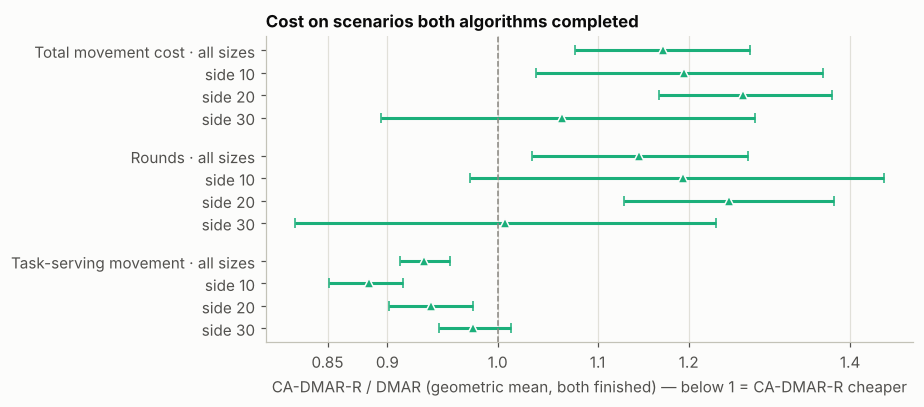

Mean movement cost over ALL runs (failed runs are censored at the cap):


,mean,lo,hi
Greedy,"3,068.858","2,267.202","3,898.181"
DMAR (baseline),"3,097.878","2,283.892","3,953.670"
CA-DMAR-R,"3,502.991","2,639.528","4,452.006"


In [8]:
Q = P[P.outcome == "both complete"].copy()
mets = {"movement_cost": "Total movement cost", "rounds": "Rounds", "task_serving_movement": "Task-serving movement"}
for c in mets: Q["lr_" + c] = np.log(Q[c] / Q[c + "_b"].replace(0, np.nan))
Q["side"] = Q.inst.str.split("|").str[0].astype(int)
out = []
for c, name in mets.items():
    for lab, sub in [("all sizes", Q)] + [(f"side {s}", Q[Q.side == s]) for s in sorted(Q.side.unique())]:
        g = sub.groupby("inst")["lr_" + c].mean()
        m, lo, hi = boot(g); out.append((name, lab, np.exp(m), np.exp(lo), np.exp(hi), len(g), len(sub)))
R = pd.DataFrame(out, columns=["metric", "subset", "ratio", "lo", "hi", "instances", "scenarios"])
display(R.style.format({"ratio": "{:.3f}", "lo": "{:.3f}", "hi": "{:.3f}"}))

fig, ax = plt.subplots(figsize=(8.5, 3.8))
ypos = {}; y = 0
for name in mets.values():
    for lab in R.subset.unique(): ypos[(name, lab)] = y; y += 1
    y += 0.7
for _, r in R.iterrows():
    yy = ypos[(r.metric, r.subset)]
    ax.errorbar(r.ratio, yy, xerr=[[r.ratio - r.lo], [r.hi - r.ratio]], fmt="^", color=COL["ca_dmar_r"], capsize=3, ms=7, mec=SURFACE)
ax.axvline(1, color=MUTED, lw=1, ls="--")
ax.set_yticks(list(ypos.values())); ax.set_yticklabels([f"{k[0]} · {k[1]}" if k[1] == "all sizes" else f"   {k[1]}" for k in ypos])
ax.invert_yaxis(); ax.set_xscale("log"); ax.set_xticks([0.85, 0.9, 1, 1.1, 1.2, 1.4]); ax.set_xticklabels(["0.85", "0.9", "1.0", "1.1", "1.2", "1.4"]); ax.minorticks_off()
ax.set_xlabel("CA-DMAR-R / DMAR (geometric mean, both finished) — below 1 = CA-DMAR-R cheaper")
ax.grid(axis="y", visible=False); ax.set_title("Cost on scenarios both algorithms completed"); plt.tight_layout(); plt.show()

# unconditioned (censored) cost, for completeness
cen = d.groupby(["algorithm", "inst"]).movement_cost.mean().unstack(0)
print("Mean movement cost over ALL runs (failed runs are censored at the cap):")
display(pd.DataFrame({LBL[a]: boot(cen[a]) for a in ALGS}, index=["mean", "lo", "hi"]).T)

## 7. Where the movement goes

`movement_cost` counts every step by every agent. Most of it is exploration (agents wandering until they see a task); only a small slice is task-serving travel — which is the part the assignment and rollout logic can actually influence.

,task_serving_movement,exploration_movement,movement_cost,explore_share,explore_share_of_all_steps
Greedy,100.704,"2,968.155","3,068.858",0.736,0.967
DMAR (baseline),110.960,"2,986.918","3,097.878",0.740,0.964
CA-DMAR-R,143.775,"3,359.216","3,502.991",0.781,0.959


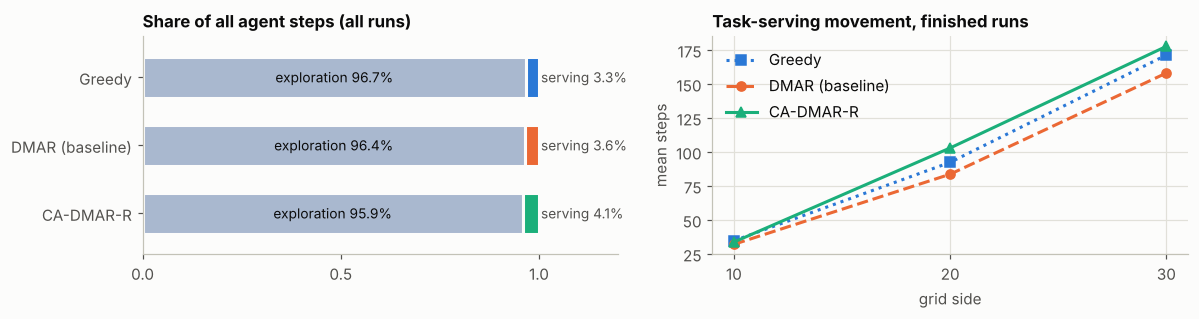

Activity (moves per agent-round), by outcome:


ok,failed,finished
algorithm,,
greedy,0.028,0.117
dmar,0.029,0.118
ca_dmar_r,0.062,0.128


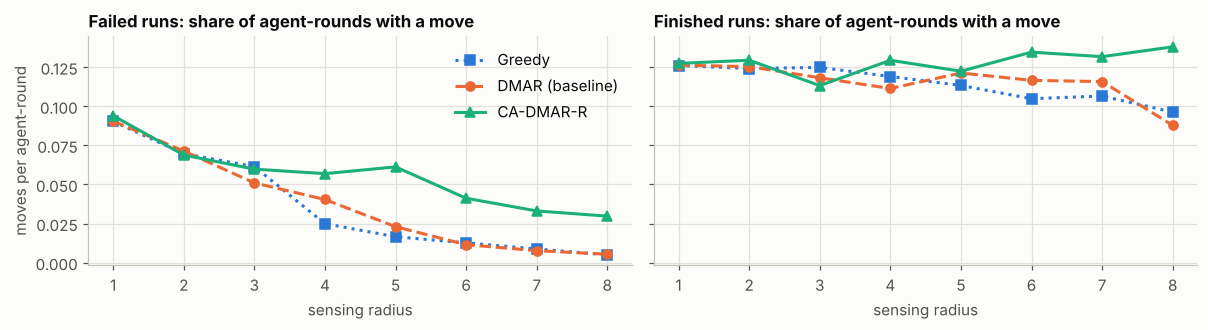

In [9]:
mv = d.groupby(["algorithm", "inst"])[["task_serving_movement", "exploration_movement", "movement_cost", "explore_share"]].mean()
summ = mv.groupby("algorithm").mean().loc[ALGS]
summ.index = [LBL[a] for a in ALGS]
summ["explore_share_of_all_steps"] = (d.groupby("algorithm").exploration_movement.sum() / d.groupby("algorithm").movement_cost.sum()).loc[ALGS].values
display(summ)

fig, axs = plt.subplots(1, 2, figsize=(11, 3.0))
sh = summ.explore_share_of_all_steps
for i, a in enumerate(ALGS):
    ax = axs[0]; e = sh.iloc[i]
    ax.barh(i, e, color="#a9b8cf", edgecolor=SURFACE, linewidth=2, height=0.6); ax.barh(i, 1 - e, left=e, color=COL[a], edgecolor=SURFACE, linewidth=2, height=0.6)
    ax.text(e / 2, i, f"exploration {e:.1%}", ha="center", va="center", fontsize=9); ax.text(1.005, i, f"serving {1 - e:.1%}", va="center", fontsize=9, color=INK2)
axs[0].set_yticks(range(3)); axs[0].set_yticklabels([LBL[a] for a in ALGS]); axs[0].set_ylim(2.6, -0.6); axs[0].set_xlim(0, 1.2); axs[0].set_xticks([0, 0.5, 1]); axs[0].grid(False)
axs[0].set_title("Share of all agent steps (all runs)")
for a in ALGS:
    s_ = d[(d.algorithm == a) & d.ok].groupby("side").task_serving_movement.mean()
    axs[1].plot(s_.index.astype(str), s_.values, marker=MRK[a], color=COL[a], label=LBL[a], ls={"greedy": ":", "dmar": "--", "ca_dmar_r": "-"}[a])
axs[1].set_title("Task-serving movement, finished runs"); axs[1].set_xlabel("grid side"); axs[1].set_ylabel("mean steps"); axs[1].legend()
plt.tight_layout(); plt.show()

# Activity: share of agent-rounds in which an agent actually moved
d["activity"] = d.movement_cost / (d.rounds * d.agent_count)
print("Activity (moves per agent-round), by outcome:")
display(d.groupby(["algorithm", "ok"]).activity.mean().unstack().rename(columns={True: "finished", False: "failed"}).loc[ALGS])
fig, axs = plt.subplots(1, 2, figsize=(11, 3.1), sharey=True)
for ax, (flag, ttl) in zip(axs, [(False, "Failed runs"), (True, "Finished runs")]):
    for a in ALGS:
        g = d[(d.algorithm == a) & (d.ok == flag)].groupby("sensing_radius").activity.mean()
        ax.plot(g.index, g.values, marker=MRK[a], color=COL[a], label=LBL[a], ls={"greedy": ":", "dmar": "--", "ca_dmar_r": "-"}[a])
    ax.set_title(ttl + ": share of agent-rounds with a move"); ax.set_xlabel("sensing radius")
axs[0].set_ylabel("moves per agent-round"); axs[0].legend(); plt.tight_layout(); plt.show()

## 8. Sensitivity to α

α only changes which agent receives a task inside the base policy, so any effect has to come through the small task-serving slice. If results hardly move with α, the capacity weighting is not the lever behind CA-DMAR-R's gain.

,completion,unresolved,rounds,movement,serving,rejected_mean,rejected_median
alpha,,,,,,,
0.250,0.803,0.385,"2,013.773","3,522.174",147.549,99.333,20.000
0.500,0.805,0.366,"2,005.884","3,511.592",140.813,98.886,20.000
0.750,0.811,0.363,"1,994.568","3,475.206",142.962,105.833,20.000


Scenarios whose movement_cost is IDENTICAL for all three alphas: 79.0%
Scenarios whose completion outcome is identical for all three alphas: 96.6%


Friedman test across alpha, per-instance completion: p = 0.676
Friedman test across alpha, per-instance rounds: p = 0.458
Friedman test across alpha, per-instance task-serving movement: p = 0.628


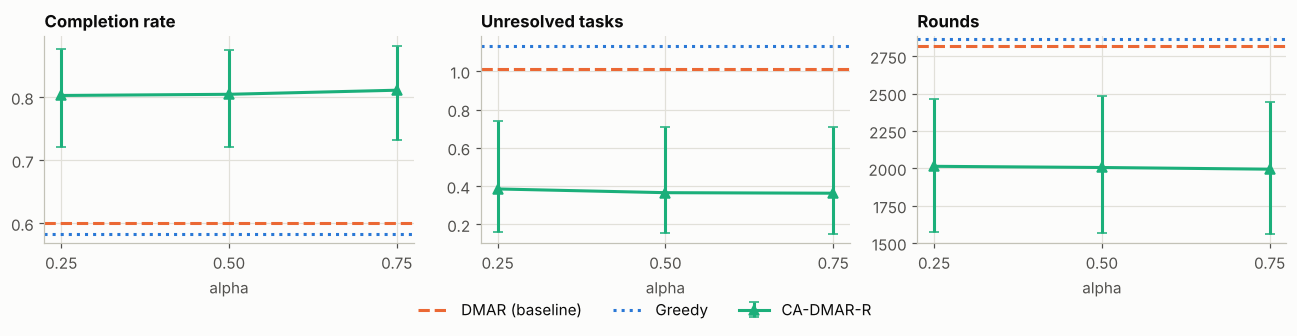

,tasks_per_agent,capacity_per_agent,scenarios_with_identical_cost_across_alpha
task_agent_ratio,,,
2:1,0.500,0.500,1.000
1:1,1.000,1.000,1.000
1:2,2.000,2.000,0.369


In [10]:
ca = d[d.algorithm == "ca_dmar_r"]
A = ca.groupby("alpha").agg(completion=("ok", "mean"), unresolved=("unresolved_tasks", "mean"), rounds=("rounds", "mean"),
                            movement=("movement_cost", "mean"), serving=("task_serving_movement", "mean"),
                            rejected_mean=("rejected_assignments", "mean"), rejected_median=("rejected_assignments", "median"))
display(A)

W = ca.pivot_table(index=K, columns="alpha", values=["movement_cost", "rounds", "ok"])
print("Scenarios whose movement_cost is IDENTICAL for all three alphas:", f"{(W['movement_cost'].nunique(axis=1) == 1).mean():.1%}")
print("Scenarios whose completion outcome is identical for all three alphas:", f"{(W['ok'].nunique(axis=1) == 1).mean():.1%}")
for col, nm in [("ok", "completion"), ("rounds", "rounds"), ("task_serving_movement", "task-serving movement")]:
    m = ca.groupby(["inst", "alpha"])[col].mean().unstack()
    print(f"Friedman test across alpha, per-instance {nm}: p = {stats.friedmanchisquare(*[m[c] for c in m.columns]).pvalue:.3g}")

fig, axs = plt.subplots(1, 3, figsize=(12, 2.9))
for ax, (col, nm) in zip(axs, [("ok", "Completion rate"), ("unresolved_tasks", "Unresolved tasks"), ("rounds", "Rounds")]):
    pts = np.array([boot(ca[ca.alpha == al].groupby("inst")[col].mean()) for al in sorted(ca.alpha.unique())])
    ax.errorbar(sorted(ca.alpha.unique()), pts[:, 0], yerr=[pts[:, 0] - pts[:, 1], pts[:, 2] - pts[:, 0]], color=COL["ca_dmar_r"], marker="^", ms=7, capsize=3, label=LBL["ca_dmar_r"])
    for a in ("dmar", "greedy"):
        ax.axhline(boot(d[d.algorithm == a].groupby("inst")[col].mean())[0], color=COL[a], ls={"dmar": "--", "greedy": ":"}[a], label=LBL[a])
    ax.set_xticks([0.25, 0.5, 0.75]); ax.set_xlabel("alpha"); ax.set_title(nm)
h, l = axs[0].get_legend_handles_labels(); fig.legend(h, l, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.06)); plt.tight_layout(); plt.show()

# Why so little alpha effect? Capacities are (nearly) uniform, so the capacity weight (R_K / r_i)^alpha is about equal for every eligible agent.
cap = d.assign(cap_per_agent=d.initial_capacity / d.agent_count).groupby("task_agent_ratio").agg(tasks_per_agent=("tpa", "first"), capacity_per_agent=("cap_per_agent", "first"))
cap["scenarios_with_identical_cost_across_alpha"] = (W["movement_cost"].nunique(axis=1) == 1).groupby(level="task_agent_ratio").mean()
display(cap.sort_values("tasks_per_agent"))

## 9. Failure structure: which instances never finish

With zero slack, an instance can be *structurally* unsolvable (a task that no agent with remaining budget can reach) and then every algorithm fails on it. Each cell is the failure rate over the 24 scenarios (8 radii × 3 runs; ×3 α for CA-DMAR-R) of one instance.

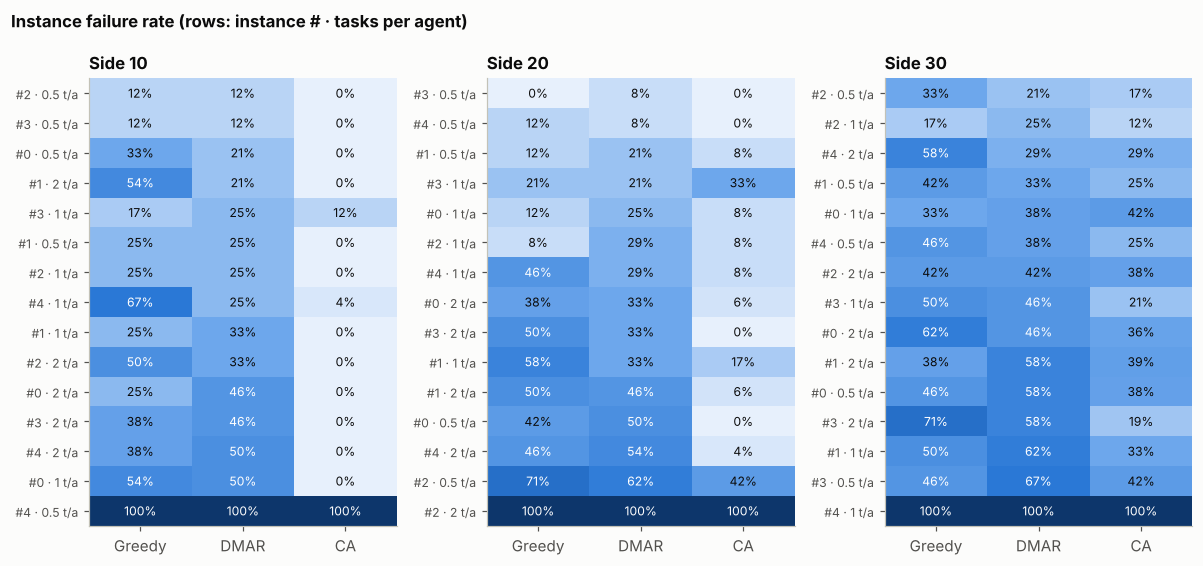

Instances failed by ALL algorithms in EVERY scenario: 3 of 45 -> ['10|4|2:1', '20|2|1:2', '30|4|1:1']
Instances with at least one failure: {'Greedy': 44, 'DMAR (baseline)': 45, 'CA-DMAR-R': 29}

Unresolved tasks in failed runs:


,count,mean,std,min,25%,50%,75%,max
algorithm,,,,,,,,
greedy,"1,350.000",2.718,2.546,1.000,1.000,2.000,3.000,15.000
dmar,"1,296.000",2.525,2.303,1.000,1.000,1.000,3.000,14.000
ca_dmar_r,628.000,1.916,1.869,1.000,1.000,1.000,2.000,10.000


In [11]:
TPA = d.groupby("task_agent_ratio").tpa.first().to_dict()   # label -> tasks per agent
F = d.groupby(["inst", "algorithm"]).fail.mean().unstack()[ALGS]
F["side"] = F.index.str.split("|").str[0].astype(int)
fig, axs = plt.subplots(1, 3, figsize=(11, 5.2))
for ax, s in zip(axs, sorted(F.side.unique())):
    M = F[F.side == s].drop(columns="side").sort_values(["dmar", "greedy", "ca_dmar_r"])
    ax.imshow(M.values, cmap=SEQ, vmin=0, vmax=1, aspect="auto")
    for i in range(M.shape[0]):
        for j in range(3):
            ax.text(j, i, f"{M.values[i, j]:.0%}", ha="center", va="center", fontsize=8, color="white" if M.values[i, j] > 0.45 else INK)
    ax.set_xticks(range(3)); ax.set_xticklabels(["Greedy", "DMAR", "CA"]); ax.set_title(f"Side {s}")
    ax.set_yticks(range(M.shape[0])); ax.set_yticklabels([f"#{i.split('|')[1]} · {TPA[i.split('|')[2]]:g} t/a" for i in M.index], fontsize=8); ax.grid(False)
plt.suptitle("Instance failure rate (rows: instance # · tasks per agent)", x=0.01, ha="left", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

always = F[(F[ALGS] == 1).all(axis=1)]
print(f"Instances failed by ALL algorithms in EVERY scenario: {len(always)} of {len(F)} -> {list(always.index)}")
print("Instances with at least one failure:", (F[ALGS] > 0).sum().rename(LBL).to_dict())
print("\nUnresolved tasks in failed runs:"); display(d[~d.ok].groupby("algorithm").unresolved_tasks.describe().loc[ALGS])

## 10. Rejected assignments

`rejected_assignments` exists only for CA-DMAR-R (always 0 for the others). The column has a very heavy tail, which suggests it counts repeated per-round rejections rather than distinct events.

{'count': 3240.0, 'mean': 101.4, 'std': 541.6, 'min': 0.0, '25%': 4.8, '50%': 20.0, '75%': 73.0, 'max': 8276.0}
top 1% of runs hold 43% of all rejections
Spearman vs rounds_with_clusters: 0.75 | vs rounds: 0.07 | vs sensing_radius: 0.68


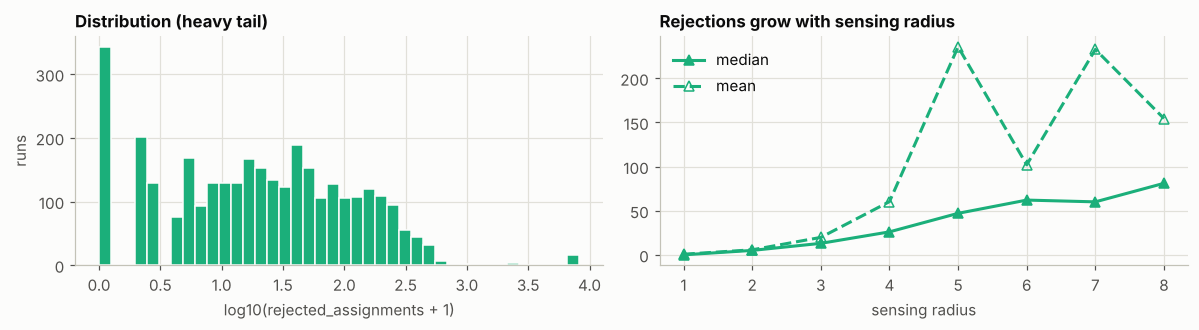

In [12]:
r = ca.rejected_assignments
print(r.describe().round(1).to_dict())
top = r.sort_values(ascending=False); print(f"top 1% of runs hold {top.head(int(len(r) * 0.01)).sum() / top.sum():.0%} of all rejections")
print("Spearman vs rounds_with_clusters:", round(stats.spearmanr(r, ca.rounds_with_clusters)[0], 2), "| vs rounds:", round(stats.spearmanr(r, ca.rounds)[0], 2),
      "| vs sensing_radius:", round(stats.spearmanr(r, ca.sensing_radius)[0], 2))
fig, axs = plt.subplots(1, 2, figsize=(11, 3.1))
axs[0].hist(np.log10(r + 1), bins=40, color=COL["ca_dmar_r"], edgecolor=SURFACE)
axs[0].set_xlabel("log10(rejected_assignments + 1)"); axs[0].set_ylabel("runs"); axs[0].set_title("Distribution (heavy tail)")
g = ca.groupby("sensing_radius").rejected_assignments.agg(["median", "mean"])
axs[1].plot(g.index, g["median"], marker="^", color=COL["ca_dmar_r"], label="median"); axs[1].plot(g.index, g["mean"], marker="^", color=COL["ca_dmar_r"], ls="--", mfc="none", label="mean")
axs[1].set_xlabel("sensing radius"); axs[1].set_title("Rejections grow with sensing radius"); axs[1].legend(); plt.tight_layout(); plt.show()

## 11. Clustering behaviour

Cluster membership is counted per round, so these counters scale with run length. Failed runs always last 5,000 rounds, which inflates their counts; the share-type metrics (exhausted agents as a fraction of members) are the more comparable ones.

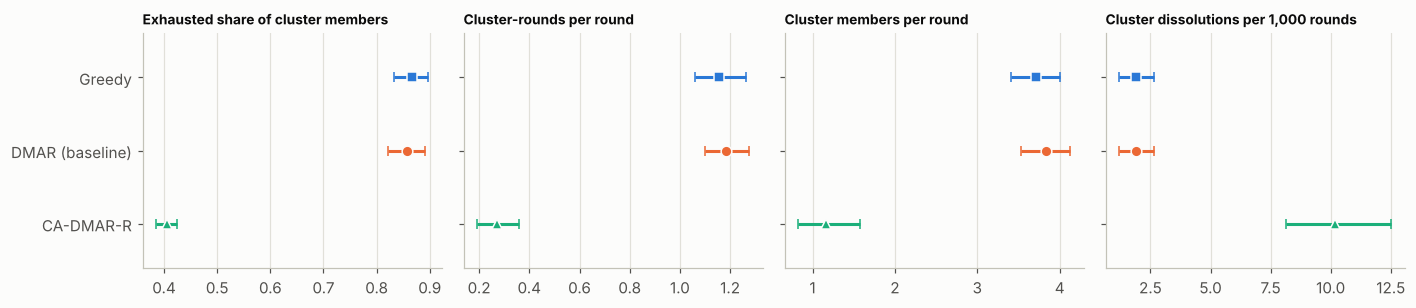

rounds_with_clusters exceeds rounds in 44% of rows (max ratio 4.1): it counts cluster-rounds, not rounds.
Exhausted share of cluster members, by algorithm and outcome:


ok,failed,finished
algorithm,,
greedy,0.941,0.812
dmar,0.939,0.803
ca_dmar_r,0.330,0.424


Largest cluster / agents clustered at least once:


,max_cluster_size,clustered_agent_share
algorithm,,
greedy,7.060,0.944
dmar,7.253,0.941
ca_dmar_r,7.260,0.943


In [13]:
d["clust_round_share"] = d.rounds_with_clusters / d.rounds
d["members_per_round"] = d.cluster_memberships / d.rounds
d["dissol_per_1k"] = d.cluster_dissolutions / d.rounds * 1000
d["clustered_agent_share"] = d.unique_clustered_agents / d.agent_count
cm = {"excl_share": "Exhausted share of cluster members", "clust_round_share": "Cluster-rounds per round",
      "members_per_round": "Cluster members per round", "dissol_per_1k": "Cluster dissolutions per 1,000 rounds"}
fig, axs = plt.subplots(1, 4, figsize=(13, 2.9))
for ax, (c, nm) in zip(axs, cm.items()):
    t = d.groupby(["algorithm", "inst"])[c].mean().unstack(0)
    for i, a in enumerate(ALGS):
        m, lo, hi = boot(t[a]); ax.errorbar(m, i, xerr=[[m - lo], [hi - m]], fmt=MRK[a], color=COL[a], ms=7, capsize=3, mec=SURFACE)
    ax.set_yticks(range(3)); ax.set_yticklabels([LBL[a] for a in ALGS] if ax is axs[0] else [""] * 3); ax.set_ylim(2.6, -0.6)
    ax.set_title(nm, fontsize=9); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

print(f"rounds_with_clusters exceeds rounds in {(d.rounds_with_clusters > d.rounds).mean():.0%} of rows (max ratio {(d.rounds_with_clusters / d.rounds).max():.1f}): it counts cluster-rounds, not rounds.")
print("Exhausted share of cluster members, by algorithm and outcome:")
display(d.groupby(["algorithm", "ok"]).excl_share.mean().unstack().rename(columns={True: "finished", False: "failed"}).loc[ALGS])
print("Largest cluster / agents clustered at least once:")
display(d.groupby("algorithm")[["max_cluster_size", "clustered_agent_share"]].mean().loc[ALGS])

## 12. Map coverage and failure type

A failed run either never *found* the remaining tasks (coverage below 100%) or found them and still did not serve them (full coverage, tasks unresolved). The second kind points at assignment or movement rather than exploration.

,failed_runs,full_coverage_share,mean_coverage
Greedy,1350,0.616,0.989
DMAR (baseline),1296,0.576,0.989
CA-DMAR-R,628,0.346,0.982


Coverage of finished runs: {'greedy': 0.988, 'dmar': 0.987, 'ca_dmar_r': 0.99}
Tasks seen by exhausted agents (per run, mean): {'greedy': 10170.0, 'dmar': 9809.0, 'ca_dmar_r': 4356.0}


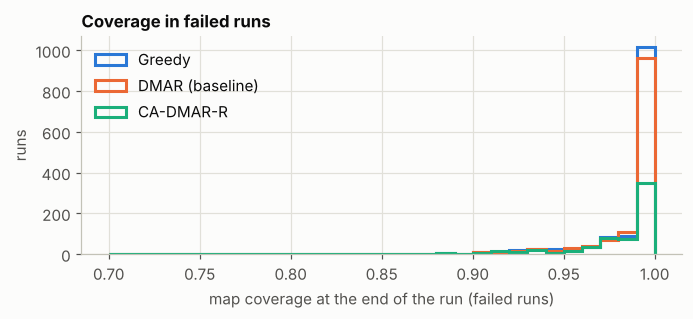

In [14]:
f = d[~d.ok].copy(); f["full_cov"] = f.coverage >= 0.9999
tt = f.groupby("algorithm").agg(failed_runs=("ok", "size"), full_coverage_share=("full_cov", "mean"), mean_coverage=("coverage", "mean")).loc[ALGS]
tt.index = [LBL[a] for a in ALGS]; display(tt)
print("Coverage of finished runs:", d[d.ok].groupby("algorithm").coverage.mean().round(3).loc[ALGS].to_dict())
print("Tasks seen by exhausted agents (per run, mean):", d.groupby("algorithm").tasks_seen_by_exhausted_agents.mean().round(0).loc[ALGS].to_dict())
fig, ax = plt.subplots(figsize=(6.4, 3))
for a in ALGS: ax.hist(f[f.algorithm == a].coverage, bins=np.linspace(0.7, 1, 31), histtype="step", lw=2, color=COL[a], label=LBL[a])
ax.set_xlabel("map coverage at the end of the run (failed runs)"); ax.set_ylabel("runs"); ax.legend(); ax.set_title("Coverage in failed runs"); plt.tight_layout(); plt.show()

## 13. Correlations (CA-DMAR-R runs, Spearman)

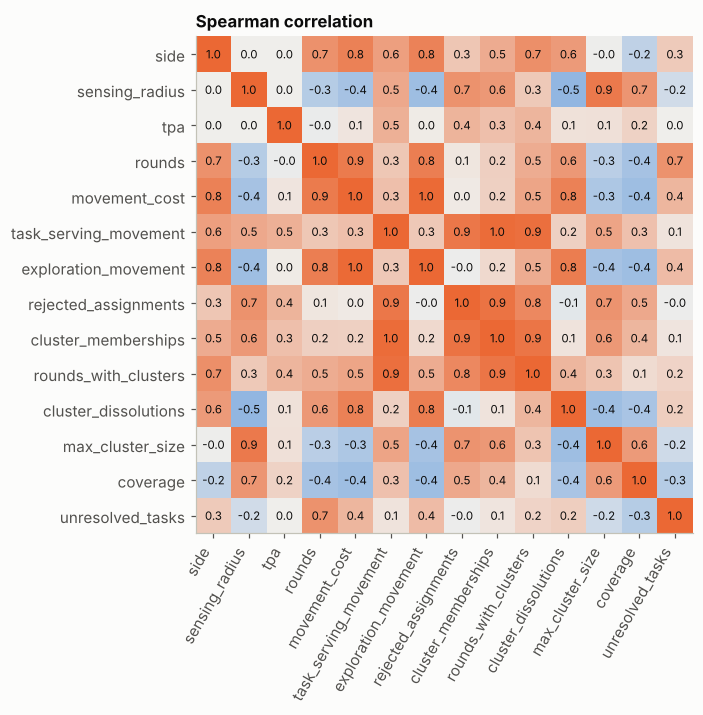

In [15]:
cc = ["side", "sensing_radius", "tpa", "rounds", "movement_cost", "task_serving_movement", "exploration_movement", "rejected_assignments",
      "cluster_memberships", "rounds_with_clusters", "cluster_dissolutions", "max_cluster_size", "coverage", "unresolved_tasks"]
Cm = ca[cc].corr(method="spearman")
fig, ax = plt.subplots(figsize=(8.2, 6.6))
ax.imshow(Cm.values, cmap=DIV, vmin=-1, vmax=1)
ax.set_xticks(range(len(cc))); ax.set_xticklabels(cc, rotation=60, ha="right"); ax.set_yticks(range(len(cc))); ax.set_yticklabels(cc)
for i in range(len(cc)):
    for j in range(len(cc)): ax.text(j, i, f"{Cm.values[i, j]:.1f}", ha="center", va="center", fontsize=7.5, color=INK)
ax.grid(False); ax.set_title("Spearman correlation"); plt.tight_layout(); plt.show()

## 14. Findings, caveats and next steps

Numbers below come from the cells above (instance-level, 45 instances; 95% bootstrap CIs in brackets).

### What the data shows

1. **CA-DMAR-R completes far more runs.** Completion is 80.6% vs 60.0% for DMAR and 58.3% for Greedy. The paired gain over DMAR is **+20.6 points** [+16.2, +25.3]; CA-DMAR-R is better on 39 of 45 instances, tied on 4 and worse on 2 (Wilcoxon p ≈ 6e-8). On matched scenarios, 27% are completed only by CA-DMAR-R and 6.5% only by DMAR. Mean unresolved tasks fall from 1.01 to 0.37.
2. **It is not cheaper where both finish.** On scenarios both completed, total movement is **×1.17** [1.08, 1.27] and rounds ×1.14 [1.03, 1.27] relative to DMAR. Task-serving movement, the part the assignment and rollout logic controls, is **×0.93** [0.91, 0.96] (×0.88 on 10×10). That is a real routing gain on a very small slice: 96–97% of all steps are exploration.
3. **The gain looks like "not stalling", not capacity weighting.**
   * α has no detectable effect: completion 80.3 / 80.5 / 81.1% for α = 0.25 / 0.5 / 0.75 (Friedman p = 0.46–0.68). The reason is visible in the data: capacities are uniform (0.5, 1 or 2 per agent), so the weight (R_K / r_i)^α is the same for every eligible agent. At 0.5 and 1 tasks per agent, results are **identical across α in 100% of scenarios**; only the 2-tasks-per-agent setting gives α anything to act on (63% of scenarios differ). **This benchmark cannot test the capacity-weighted score.**
   * Baseline failures grow with sensing radius (DMAR 27% → 69% from radius 1 to 8; Greedy reaches 73%), while CA-DMAR-R falls (30% → 12%). On 10×10 at radius 8: 87% vs 7%.
   * Failed baseline runs at radius ≥ 6 are almost frozen: about 1% of agent-rounds contain a move, against 3–4% for CA-DMAR-R.
   * Baseline clusters are mostly exhausted agents (about 86% of members vs about 40% for CA-DMAR-R), and 58–62% of baseline failures had already covered the whole map yet left tasks unresolved (35% for CA-DMAR-R). Those failures are stalls, not search failures.
4. **Two distinct failure regimes.** *Exploration-limited:* large map, small radius (side 30, radius 1–2) fails 53–60% for **every** algorithm including CA-DMAR-R, because 5,000 rounds is not enough to find the tasks. *Stall-limited:* large radius, where the baselines collapse and CA-DMAR-R does not.
5. **A completion ceiling exists.** 3 of 45 instances (`10|4|2:1`, `20|2|1:2`, `30|4|1:1`) fail for every algorithm in every scenario. With zero capacity slack this is probably structural, so completion cannot exceed about 93%.

### Data and measurement caveats

* **Zero slack and censoring.** Capacity equals task count, so every unserved task is also unused capacity, and all failed runs are cut at 5,000 rounds. Cost and rounds are only comparable on commonly finished scenarios (and then conditional on finishing).
* **Exhausted-agent counters contradict each other** (`exhausted_movement` and `exhausted_clustered_rounds` are 0 in every row, while exhausted agents are counted as cluster members and `exhausted_exploration` is 1). Treat them as unreliable until the simulator is checked.
* **`rounds_with_clusters` counts cluster-rounds, not rounds** (it exceeds `rounds` in 44% of rows), so the name is misleading.
* **No ablation information:** `soac_mode`, `assignment_mode` and `exhausted_exploration` are constant, so the effect of each CA-DMAR-R modification (leader eligibility, pressure-guided joining, regret/weighting, capacity-aware rollout) cannot be separated.
* `rejected_assignments` is extremely heavy-tailed (median 20, max 8,276; the top 1% of runs hold 43% of the total), so it probably counts repeated per-round rejections.
* Only 45 instances: the CIs are wide, and results by side have 15 instances each.